# Árvores de Decisão

As arvores de decisões são algoritmos simples, porem muito eficientes em classificar. Podendo ser usado para regressões, porem não como a mesma eficiência.

São baseadas em "codições" para estabelecer divisões nos conjuntos de dados, essa divisão é baseada em qual valor ou classe entre as variáveis preditoras estabelece a melhor redução da entropia. Por meio de dois índices para classificação:

* Gini : 1-∑(p)², onde p é a probabilidade dos elementos serem dividos em clases distintas.

* Ganho de informação:-∑plog2(p)

* RSS ∑(y-y')², para regressões

 **Objetivo:**
 1.  Carregar e preparar o dataset Iris.
 2.  Treinar um `DecisionTreeClassifier`.
 3.  **Visualizar a árvore gerada**, mostrando as regras (splits) que o modelo aprendeu.
 4.  Avaliar a performance do modelo no conjunto de teste.

 Árvores de decisão são modelos do tipo "white-box" (caixa-branca), pois sua lógica interna é totalmente interpretável, como veremos no gráfico.

In [ ]:
# Importação das Bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree # A função principal para visualização
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configurações de visualização
sns.set_theme(style="whitegrid", context="talk")


# Preparação dos Dados

O dataset Iris possui 4 features (características) e 3 classes (espécies de flor).
 - **Features:** Comprimento e Largura da Sépala, Comprimento e Largura da Pétala.
- **Classes:** Setosa, Versicolor, Virginica.

 Vamos carregar os dados, dividi-los em features (X) e alvo (y), e então separar em conjuntos de treino e teste.


In [ ]:
# Preparação

# Carregar o dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

# Visualizar os dados em um DataFrame (opcional, mas bom para os alunos)
df = pd.DataFrame(X, columns=feature_names)
df['species'] = y
df['species_name'] = df['species'].map(dict(enumerate(class_names)))
print("--- Amostra do Dataset Iris ---")
print(df.head())
print("\n")

# Separar em dados de Treino e Teste
# 30% dos dados serão para teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2025)

print(f"Formato de X_train (treino): {X_train.shape}")
print(f"Formato de X_test (teste): {X_test.shape}")


--- Amostra do Dataset Iris ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species species_name  
0        0       setosa  
1        0       setosa  
2        0       setosa  
3        0       setosa  
4        0       setosa  


Formato de X_train (treino): (105, 4)
Formato de X_test (teste): (45, 4)



#  Treinamento do Modelo de Árvore de Decisão

 Vamos instanciar o `DecisionTreeClassifier`.

 **Parâmetro Chave:** `max_depth=3`

Definimos uma profundidade máxima de 3. Isso é crucial para a visualização:
 1.  Evita que a árvore cresça demais e fique ilegível.
 2.  Funciona como uma técnica de **regularização** para prevenir overfitting (excesso de ajuste) aos dados de treino.


In [ ]:

# Instanciar o classificador
clf = DecisionTreeClassifier(
    criterion='gini',   # Critério de divisão (Impureza Gini ou Entropia)
    max_depth=3,        # Profundidade máxima (para interpretabilidade)
    random_state=2025     # Para reprodutibilidade
)

# Treinar o modelo
clf.fit(X_train, y_train)

print(f"Profundidade da árvore: {clf.get_depth()}")

Profundidade da árvore: 3



# Visualização da Árvore Gerada

Usamos a função `plot_tree` do `sklearn`.

**Interpretando o Gráfico:**
 - **Nó Raiz (Topo):** A primeira decisão (split) que melhor divide os dados.
 - **`feature_name <= value`:** A regra de decisão.
 - **`gini`:** A medida de impureza do nó (0.0 = perfeitamente puro).
 - **`samples`:** O número de amostras de treino naquele nó.
 - **`value = [X, Y, Z]`:** A distribuição das amostras entre as classes (ex: [34 setosa, 32 versicolor, 39 virginica]).
 - **`class`:** A classe majoritária naquele nó.
 - **Nós Folha (Base):** Os nós terminais que fazem a previsão final.



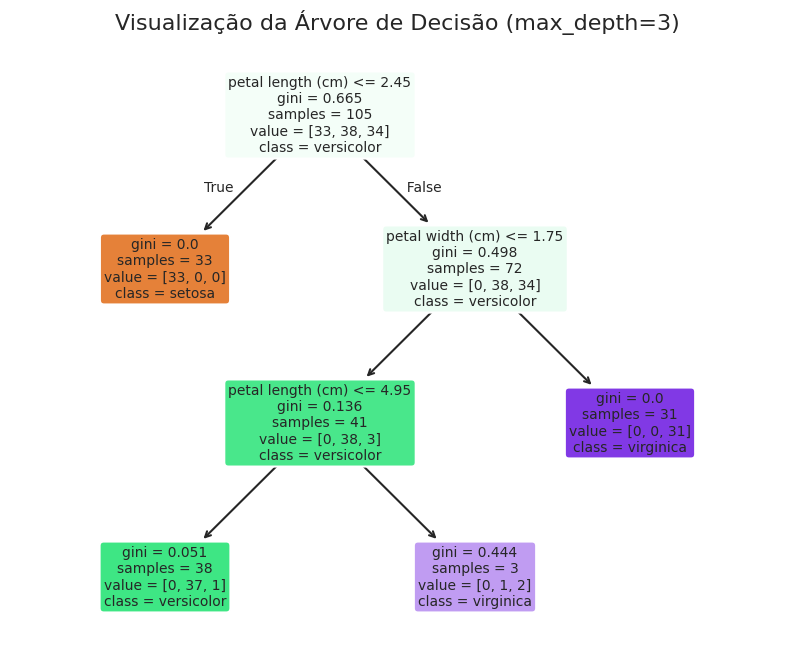

In [ ]:
# Código de Plotagem da Árvore

plt.figure(figsize=(10, 8))  # Define um tamanho grande para a figura

# Podemos alterar as infos
plot_tree(
    clf, # O modelo treinado
    feature_names=feature_names, # Nomes das features
    class_names=class_names,     # Nomes das classes (alvo)
    filled=True,                 # Colore os nós pela classe majoritária
    rounded=True,                # Caixas com cantos arredondados
    fontsize=10,     # Tamanho da fonte

    )

plt.title("Visualização da Árvore de Decisão (max_depth=3)", fontsize=16)
plt.show()


# Avaliação da Performance

A visualização é ótima para *interpretar*, mas precisamos de métricas quantitativas para *avaliar* o quão bem o modelo generaliza para dados novos (o set de teste).

#


Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        17
  versicolor       1.00      0.83      0.91        12
   virginica       0.89      1.00      0.94        16

    accuracy                           0.96        45
   macro avg       0.96      0.94      0.95        45
weighted avg       0.96      0.96      0.95        45


Matriz de Confusão:


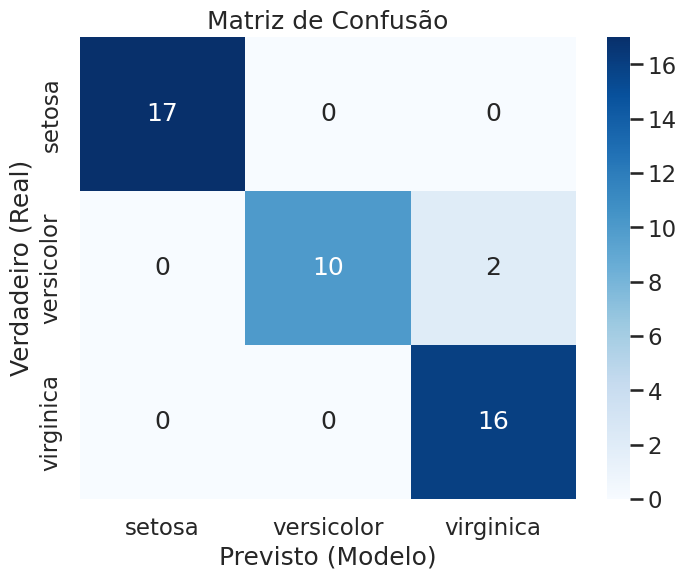

In [ ]:


# Fazer previsões no set de teste
y_pred = clf.predict(X_test)

# Relatório de Classificação (Precisão, Recall, F1-Score)
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=class_names))

# Matriz de Confusão
print("\nMatriz de Confusão:")
cm = confusion_matrix(y_test, y_pred)

# Plotar a Matriz de Confusão com Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusão')
plt.ylabel('Verdadeiro (Real)')
plt.xlabel('Previsto (Modelo)')
plt.show()




 **Conclusão da Análise:**

 Como podemos ver no gráfico, a árvore aprendeu regras claras, como "se `petal length (cm) <= 2.45`", o nó se torna puro (gini = 0.0) e é classificado como `setosa`.

As métricas de avaliação mostram que, mesmo limitada a uma profundidade de 3, a árvore atinge uma acurácia muito alta

Atividade:  Modifique a relação teste/treino, profundidade da arvore, bem como a seed para ver quais impactos temos sobre os valores gerados.

Agora vamos trabalhar com os dados do titanic

Observe que temos que definir os parametros de parada de crescimento:

* custo de complexidade (cost_complexity=0.01) (poda, ou seja, mesmo aumentando a complexidade (profundidade) não tem uma melhora significativa no modelo)
* profundadida da arvore (tree_depth=6)
* Tamanho minimo da folha (min_n=2)

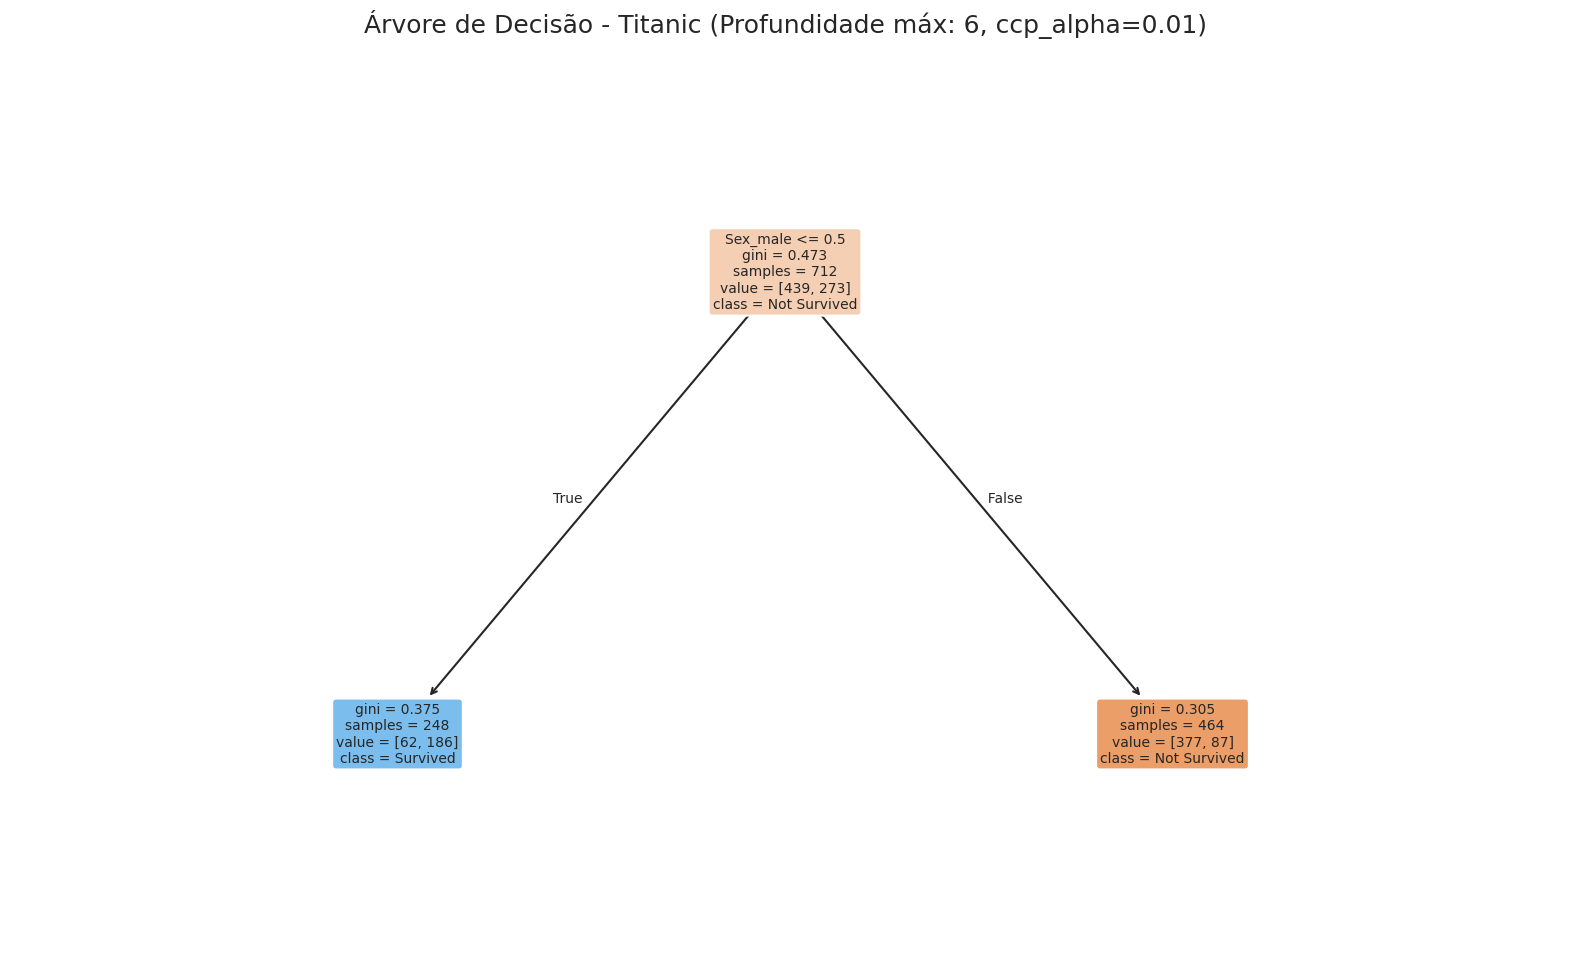

|--- Sex_male <= 0.50
|   |--- class: 1
|--- Sex_male >  0.50
|   |--- class: 0



In [ ]:
# Carregar os dados
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
titanic = pd.read_csv(url)

# Converter colunas com menos de 10 valores únicos para category
def n_distinct(col):
    return col.nunique()

# Aplicar apenas em colunas com < 10 valores únicos
for col in titanic.columns:
    if n_distinct(titanic[col]) < 10:
        titanic[col] = titanic[col].astype('category')

# Split estratificado com seed fixo
np.random.seed(2024)
df_train, df_test = train_test_split(
    titanic,
    test_size=0.20,
    stratify=titanic['Survived'],
    random_state=2024
)

# Preparar features (apenas Age, Pclass, Sex)
X_train = df_train[['Age', 'Pclass', 'Sex']]
y_train = df_train['Survived']

X_test = df_test[['Age', 'Pclass', 'Sex']]
y_test = df_test['Survived']

# One-hot encoding para 'Sex' e 'Pclass' (já que são categóricas)
X_train = pd.get_dummies(X_train, columns=['Sex', 'Pclass'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['Sex', 'Pclass'], drop_first=True)

# Árvore de Decisão com parâmetros equivalentes
decision_tree_model = DecisionTreeClassifier(
    ccp_alpha=0.05,          # cost_complexity
    max_depth=12,            # tree_depth
    min_samples_split=2,     # min_n (mínimo por nó para split)
    random_state=25
)

# Ajustar o modelo
dt_fit = decision_tree_model.fit(X_train, y_train)

# 7. Mostrar a árvore
plt.figure(figsize=(20, 12))
plot_tree(
    dt_fit,
    feature_names=X_train.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=5  # limitar visualização (opcional, senão fica gigante)
)
plt.title("Árvore de Decisão - Titanic (Profundidade máx: 6, ccp_alpha=0.01)")
plt.show()

# imprimir texto da árvore (regras)
from sklearn.tree import export_text
tree_rules = export_text(dt_fit, feature_names=list(X_train.columns))
print(tree_rules)

In [ ]:
y_pred = dt_fit.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['Not Survived', 'Survived']))


              precision    recall  f1-score   support

Not Survived       0.81      0.83      0.82       110
    Survived       0.71      0.68      0.70        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.76       179
weighted avg       0.77      0.77      0.77       179



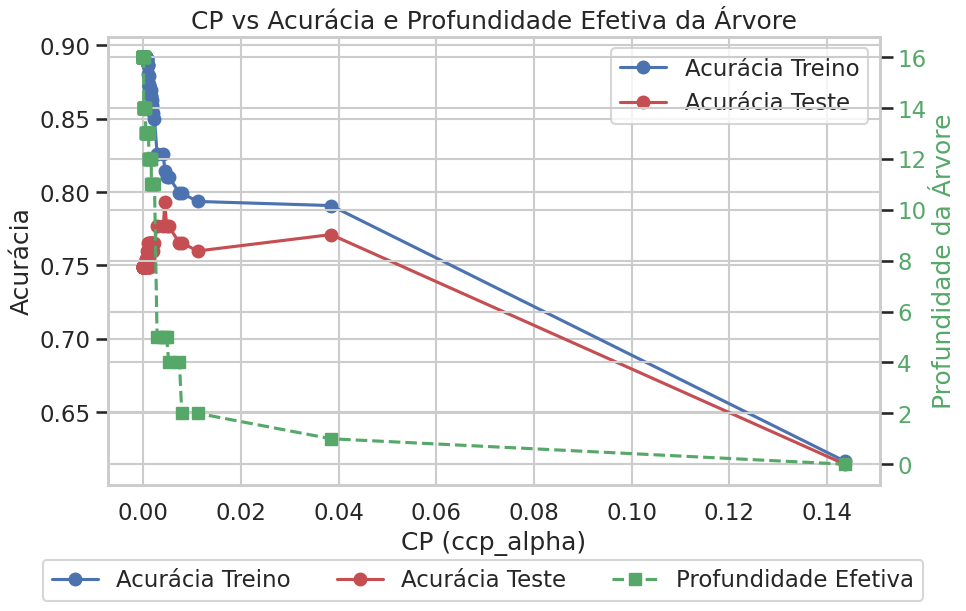

In [ ]:
# ÁRVORE SEM Poda PARA EXTRair CAMINHO DE CP
clf = DecisionTreeClassifier(max_depth=30, min_samples_split=2, random_state=25)
clf.fit(X_train, y_train)

path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

#TREINAR UMA ÁRVORE PARA CADA CP
train_scores = []
test_scores = []
effective_depths = []

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(
        random_state=2024,
        ccp_alpha=alpha,
        max_depth=30,
        min_samples_split=2
    )
    tree.fit(X_train, y_train)
    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))
    effective_depths.append(tree.get_depth())

# CP vs ACURÁCIA + PROFUNDIDADE ---
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(ccp_alphas, train_scores, 'b-o', label='Acurácia Treino')
ax1.plot(ccp_alphas, test_scores, 'r-o', label='Acurácia Teste')
ax1.set_xlabel("CP (ccp_alpha)")
ax1.set_ylabel("Acurácia")
ax1.legend(loc="upper right")
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(ccp_alphas, effective_depths, 'g--s', label='Profundidade Efetiva')
ax2.set_ylabel("Profundidade da Árvore", color='g')
ax2.tick_params(axis='y', labelcolor='g')

plt.title("CP vs Acurácia e Profundidade Efetiva da Árvore")
fig.legend(loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=3)
plt.tight_layout()
plt.show()


In [ ]:
ccp_alphas

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 4.56004669e-06, 1.33761370e-05,
       2.55362615e-05, 2.73602802e-05, 3.54074214e-05, 4.01284109e-05,
       4.25604358e-05, 5.35045479e-05, 6.68806849e-05, 9.22291797e-05,
       1.23121261e-04, 1.33761370e-04, 1.40449438e-04, 1.40449438e-04,
       2.00642055e-04, 2.10674157e-04, 2.34082397e-04, 2.34082397e-04,
       2.34082397e-04, 2.65368772e-04, 3.06435138e-04, 3.74531835e-04,
       4.29151061e-04, 5.61797753e-04, 5.85205993e-04, 6.24219725e-04,
       6.28326434e-04, 6.86958025e-04, 7.02247191e-04, 7.49063670e-04,
       7.81122781e-04, 8.02568218e-04, 9.36329588e-04, 9.64045908e-04,
       1.04097819e-03, 1.09605640e-03, 1.12359551e-03, 1.16372392e-03,
       1.22893258e-03, 1.24843945e-03, 1.25304199e-03, 1.27024124e-03,
       1.34307493e-03, 1.53217569e-03, 1.64404884e-03, 1.71074447e-03,
       1.75926601e-03, 1.80427431e-03, 1.89796538e-03, 2.00034048e-03,
      

# Bagging Tree

O processo de arvores ensacadas funciona com um processo interno de reamostragem via bootstrap, no qual para cada conjunto de reamostragem é treinada uma arvore independente, no final todas votam, para classificação a classe é escolhida pela Moda, para regressão a media.

In [ ]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
# ÁRVORE BASE (com seus parâmetros)
base_tree = DecisionTreeClassifier(
    ccp_alpha=0.01,
    max_depth=6,
    min_samples_split=2,
    random_state=25
)

# BAGGING
bagging_model = BaggingClassifier(
    estimator=base_tree,        # sua árvore com CP=0.01, depth=18, min_n=2
    n_estimators=100,           # número de árvores
    max_samples=0.8,            # 80% dos dados por árvore (bootstrap)
    bootstrap=True,             # com reposição (padrão do bagging)
    random_state=25,
    n_jobs=-1                   # paralelizar
)

#  TREINAR
bagging_model.fit(X_train, y_train)

# PREVER E AVALIAR
y_pred_tree = base_tree.fit(X_train, y_train).predict(X_test)
y_pred_bag = bagging_model.predict(X_test)

acc_tree = accuracy_score(y_test, y_pred_tree)
acc_bag = accuracy_score(y_test, y_pred_bag)

print(f"Acurácia Árvore Única: {acc_tree:.4f}")
print(f"Acurácia Bagging (100 árvores): {acc_bag:.4f}")
print(f"Melhora: {acc_bag - acc_tree:.4f} (+{(acc_bag - acc_tree)*100:.2f}%)")



Acurácia Árvore Única: 0.7654
Acurácia Bagging (100 árvores): 0.7709
Melhora: 0.0056 (+0.56%)


# Random forest

Mesmo processo da Bagging Tree, porem agora as colunas entram no sorteio, ou seja, nem todas variaveis são selecionadas.

Árvore Única: 0.7654
Bagging: 0.7709
Random Forest: 0.7765


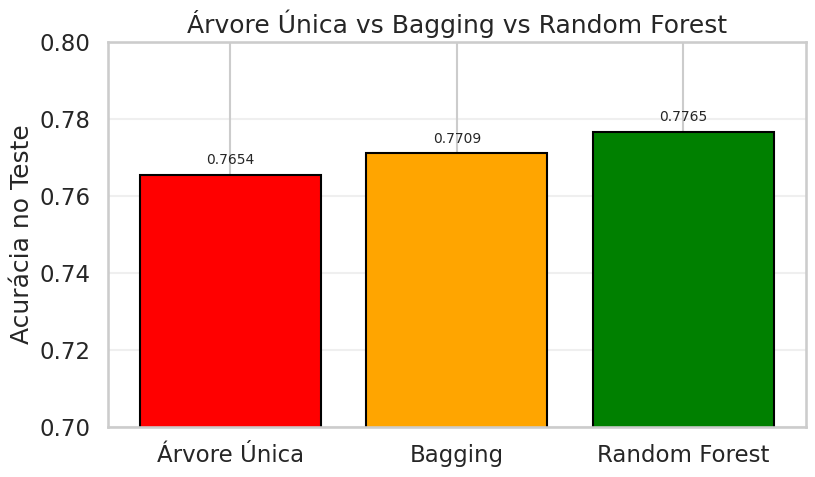

In [ ]:
#


# RANDOM FOREST
rf = RandomForestClassifier(
    n_estimators=100,
    ccp_alpha=0.01,
    max_depth=6,
    min_samples_split=2,
    max_features='sqrt',        # padrão do RF: aleatoriedade nas features
    bootstrap=True,
    random_state=25,
    n_jobs=-1
)

# TREINA

rf.fit(X_train, y_train)

# PREVER E AVALIAR
models = {'Árvore Única': base_tree, 'Bagging': bagging_model, 'Random Forest': rf}
results = {}

for name, model in models.items():
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    results[name] = acc
    print(f"{name}: {acc:.4f}")

# GRÁFICO: Comparação de desempenho
plt.figure(figsize=(9, 5))
names = list(results.keys())
accs = list(results.values())

bars = plt.bar(names, accs, color=['red', 'orange', 'green'], edgecolor='black')
plt.ylabel("Acurácia no Teste")
plt.title("Árvore Única vs Bagging vs Random Forest")
plt.ylim(0.70, 0.80)

# Adicionar valores nas barras
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.002,
             f'{height:.4f}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', alpha=0.3)
plt.show()

## Boost Tree

Modelo similar ao random forest, porem agora as arvores são dependentes, onde o erro é propagada para a próxima arvore que tenta corrigi-lo (existem diversas arquiteturas de consuzir esse processo). Este modelo quando bem ajustado evitando o overffiteng é superior aos demais. Este modelo possui diversos parâmetros a serem ajustados, que veremos mais a frente como otimizá-los

Árvore Única: 0.7430
Bagging: 0.7654
Random Forest: 0.7765
XGBoost: 0.8045


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [16:38:17] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


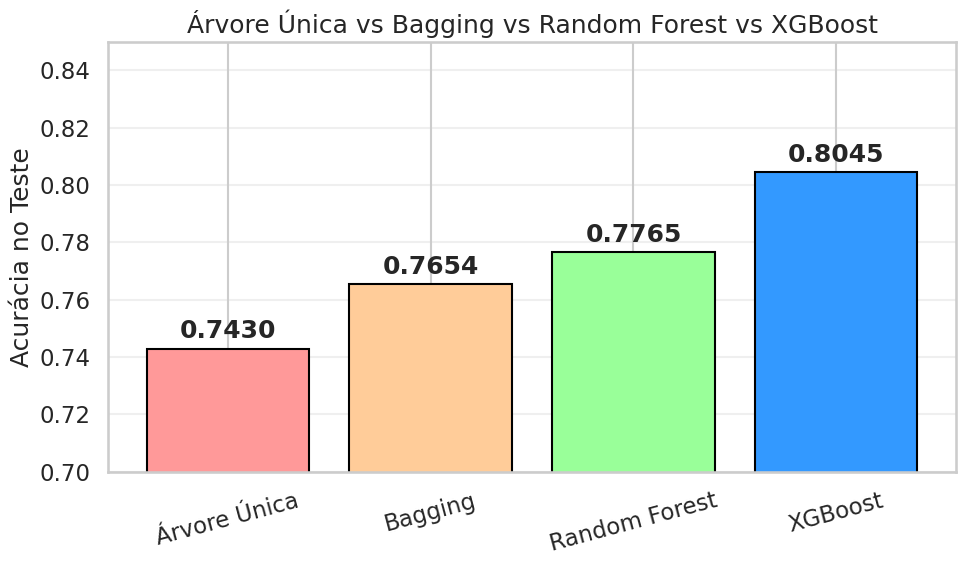

<Figure size 800x400 with 0 Axes>

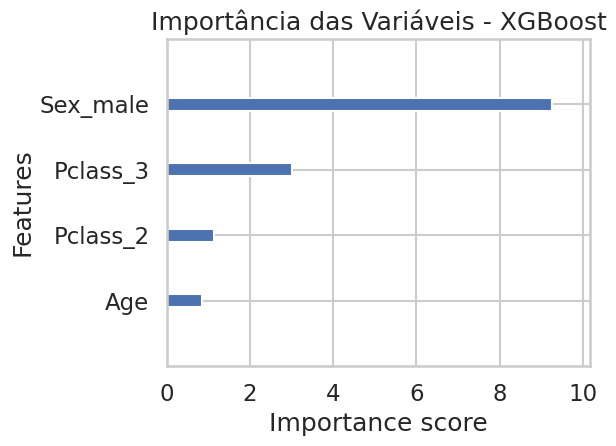

In [ ]:
from xgboost import XGBClassifier

# MODELOS
models = {}

# Árvore Única
models['Árvore Única'] = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=2,
    ccp_alpha=0.001,
    random_state=25
)

# Bagging
models['Bagging'] = BaggingClassifier(
    estimator=models['Árvore Única'],
    n_estimators=100,
    max_samples=0.8,
    random_state=25,
    n_jobs=-1
)

# Random Forest
models['Random Forest'] = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_split=2,
    max_features='sqrt',
    random_state=25,
    n_jobs=-1
)

# XGBoost
models['XGBoost'] = XGBClassifier(
    n_estimators=100,
    max_depth=6,                    # profundidade maxima
    min_child_weight=1,              # quanto dados podem ter em uma folha = min_samples_split
    learning_rate=0.1,               # eta, quanto menor + arvores é necessario
    subsample=0.8,                    # quanto % dos dados serão pegos para cada arvore
    colsample_bytree=0.8,            # como max_features
    objective='binary:logistic', # obrigatorio: define o que problemas vamos resolver 'reg:squarederror'
    random_state=2024,
    n_jobs=-1,
    eval_metric='logloss',  # earlingstop
    use_label_encoder=False
)

# TREINAR E AVALIAR
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    results[name] = acc
    print(f"{name}: {acc:.4f}")

# GRÁFICO FINAL: Comparação
plt.figure(figsize=(10, 6))
names = list(results.keys())
accs = list(results.values())

bars = plt.bar(names, accs, color=['#ff9999', '#ffcc99', '#99ff99', '#3399ff'], edgecolor='black')
plt.ylabel("Acurácia no Teste")
plt.title("Árvore Única vs Bagging vs Random Forest vs XGBoost")
plt.ylim(0.70, 0.85)

# Valores nas barras
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.002,
             f'{accs[i]:.4f}', ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# IMPORTÂNCIA DAS VARIÁVEIS (XGBoost)
from xgboost import plot_importance
plt.figure(figsize=(8, 4))
plot_importance(models['XGBoost'], max_num_features=10, importance_type='gain', show_values=False)
plt.title("Importância das Variáveis - XGBoost")
plt.tight_layout()
plt.show()

O SHAP (SHapley Additive exPlanations) serve para determinar a explicabilidade de modelos de Machine Learning. Ele resolve o problema da "caixa-preta" (black-box) em modelos complexos (como Random Forests, XGBoost e Redes Neurais), permitindo entender exatamente como e o quanto cada variável (feature) influenciou uma predição específica.

/tmp/ipython-input-514055314.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, plot_type="bar") #


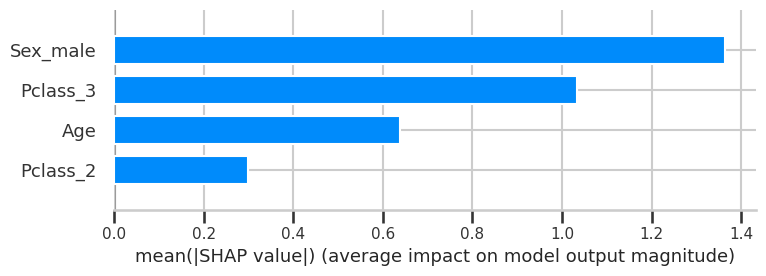

In [ ]:
import shap

explainer = shap.TreeExplainer(models['XGBoost'])# pode ser qualquer modelo
shap_values = explainer.shap_values(X_test)

#
shap.summary_plot(shap_values, X_test, plot_type="bar") #



qual esta certo?

A variavel de importancia é global, qual o impacto da variavel em melhorar o erro do modelo, ja o SHAP leva em conta tambem o LOCAL, como foi em cada arvore. Considera interações (ex: Age só importa se Sex_male=1)

Logo prefira o SHAP